In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

In [3]:
df = pd.read_excel(
    "Combined Data VF.ods",
    engine="odf"
)

df.head()

,sample_no,day_no,end_of_sample_status,Unnamed: 3,run_count,running_distance_km,running_elapsed_time,avg_ground_contact_ms,avg_cadence_spm,avg_running_heart_rate_bpm,...,weekly_avg_hrv_ms,sleep_duration,sleep_score,deep_sleep_duration,light_sleep_duration,rem_sleep_duration,awake_duration,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,1,1,Healthy,NaN,1,10.01,00:48:00,239.9,179.5,161.0,...,98,06:57:00,64.0,01:08:00,05:29:00,00:20:00,00:40:00,NaN,NaN,NaN
1,1,2,Healthy,NaN,1,10.01,00:48:00,239.3,178.4,154.0,...,99,06:11:00,62.0,00:54:00,04:38:00,00:39:00,00:49:00,NaN,NaN,NaN
2,1,3,Healthy,NaN,1,5.23,00:26:00,246.5,174.0,156.0,...,98,06:59:00,66.0,00:53:00,05:32:00,00:34:00,00:47:00,NaN,NaN,NaN
3,1,4,Healthy,NaN,1,10.01,00:49:00,242.4,175.5,159.0,...,98,08:09:00,85.0,00:52:00,05:27:00,01:50:00,00:03:00,NaN,NaN,NaN
4,1,5,Healthy,NaN,1,7.32,00:35:00,243.8,175.6,150.0,...,97,08:23:00,81.0,01:20:00,05:38:00,01:26:00,00:23:00,NaN,NaN,NaN


In [4]:
df = df.dropna(axis=1, how="all")

print(df.columns.tolist())

['sample_no', 'day_no', 'end_of_sample_status', 'run_count', 'running_distance_km', 'running_elapsed_time', 'avg_ground_contact_ms', 'avg_cadence_spm', 'avg_running_heart_rate_bpm', 'avg_elapsed_pace_min_per_km', 'avg_stride_length_m', 'resting_heart_rate_bpm', 'avg_stress_level', 'nightly_hrv_ms', 'weekly_avg_hrv_ms', 'sleep_duration', 'sleep_score', 'deep_sleep_duration', 'light_sleep_duration', 'rem_sleep_duration', 'awake_duration', 'Unnamed: 25']


In [5]:
print("Number of samples:", df["sample_no"].nunique())

sample_sizes = df.groupby("sample_no").size()

print(sample_sizes)

Number of samples: 33
sample_no
1     30
2     30
3     30
4     30
5     30
6     30
7     30
8     30
9     30
10    30
11    30
12    30
13    30
14    30
15    30
16    30
17    30
18    30
19    30
20    30
21    30
22    30
23    30
24    30
25    30
26    30
27    30
28    30
29    30
30    30
31    30
32    30
33    30
dtype: int64


In [6]:
print(sample_sizes.value_counts())

30    33
Name: count, dtype: int64


In [7]:
sample_labels = (
    df.groupby("sample_no")["end_of_sample_status"]
    .first()
)

print(sample_labels.value_counts())

end_of_sample_status
Healthy    28
Injured     5
Name: count, dtype: int64


In [8]:
time_columns = [
    "running_elapsed_time",
    "avg_elapsed_pace_min_per_km",
    "sleep_duration",
    "deep_sleep_duration",
    "light_sleep_duration",
    "rem_sleep_duration",
    "awake_duration"
]

In [9]:
def time_to_minutes(value):
    if pd.isna(value):
        return np.nan

    value = str(value)

    try:
        parts = value.split(":")

        hours = float(parts[0])
        minutes = float(parts[1])
        seconds = float(parts[2])

        return hours * 60 + minutes + seconds / 60

    except:
        return np.nan

In [10]:
for column in time_columns:
    df[column] = df[column].apply(time_to_minutes)

In [11]:
df[time_columns].head()

,running_elapsed_time,avg_elapsed_pace_min_per_km,sleep_duration,deep_sleep_duration,light_sleep_duration,rem_sleep_duration,awake_duration
0,48.0,287.0,417.0,68.0,329.0,20.0,40.0
1,48.0,286.0,371.0,54.0,278.0,39.0,49.0
2,26.0,299.0,419.0,53.0,332.0,34.0,47.0
3,49.0,293.0,489.0,52.0,327.0,110.0,3.0
4,35.0,289.0,503.0,80.0,338.0,86.0,23.0


In [12]:
features = [
    "running_distance_km",
    "running_elapsed_time",
    "avg_ground_contact_ms",
    "avg_cadence_spm",
    "avg_running_heart_rate_bpm",
    "avg_stride_length_m",
    "resting_heart_rate_bpm",
    "avg_stress_level",
    "nightly_hrv_ms",
    "weekly_avg_hrv_ms",
    "sleep_score"
]

In [13]:
data = df[
    ["sample_no", "day_no", "end_of_sample_status", "run_count"] + features
].copy()

In [14]:
data["ran_today"] = (data["run_count"] > 0).astype(int)

In [15]:
data.head()

,sample_no,day_no,end_of_sample_status,run_count,running_distance_km,running_elapsed_time,avg_ground_contact_ms,avg_cadence_spm,avg_running_heart_rate_bpm,avg_stride_length_m,resting_heart_rate_bpm,avg_stress_level,nightly_hrv_ms,weekly_avg_hrv_ms,sleep_score,ran_today
0,1,1,Healthy,1,10.01,48.0,239.9,179.5,161.0,1.189,47,29,92,98,64.0,1
1,1,2,Healthy,1,10.01,48.0,239.3,178.4,154.0,1.219,50,27,96,99,62.0,1
2,1,3,Healthy,1,5.23,26.0,246.5,174.0,156.0,1.203,51,29,90,98,66.0,1
3,1,4,Healthy,1,10.01,49.0,242.4,175.5,159.0,1.220,49,29,95,98,85.0,1
4,1,5,Healthy,1,7.32,35.0,243.8,175.6,150.0,1.216,47,22,99,97,81.0,1


In [16]:
data["running_distance_km"] = data["running_distance_km"].fillna(0)
data["running_elapsed_time"] = data["running_elapsed_time"].fillna(0)

In [17]:
mechanics_columns = [
    "avg_ground_contact_ms",
    "avg_cadence_spm",
    "avg_running_heart_rate_bpm",
    "avg_stride_length_m"
]

data[mechanics_columns] = (
    data
    .groupby("sample_no")[mechanics_columns]
    .transform(lambda x: x.interpolate(limit_direction="both"))
)

In [18]:
recovery_columns = [
    "resting_heart_rate_bpm",
    "avg_stress_level",
    "nightly_hrv_ms",
    "weekly_avg_hrv_ms",
    "sleep_score"
]

data[recovery_columns] = (
    data
    .groupby("sample_no")[recovery_columns]
    .transform(lambda x: x.interpolate(limit_direction="both"))
)

In [19]:
data[features].isna().sum()

running_distance_km           0
running_elapsed_time          0
avg_ground_contact_ms         0
avg_cadence_spm               0
avg_running_heart_rate_bpm    0
avg_stride_length_m           0
resting_heart_rate_bpm        0
avg_stress_level              0
nightly_hrv_ms                0
weekly_avg_hrv_ms             0
sleep_score                   0
dtype: int64

In [20]:
data = data.sort_values(
    ["sample_no", "day_no"]
).reset_index(drop=True)

In [21]:
data[["sample_no", "day_no"]].head(35)

,sample_no,day_no
0,1,1
1,1,2
2,1,3
3,1,4
4,1,5
5,1,6
6,1,7
7,1,8
8,1,9
9,1,10


In [22]:
X = np.array([
    group[features].to_numpy().T
    for _, group in data.groupby("sample_no")
])

In [23]:
print(X.shape)

(33, 11, 30)


In [24]:
y = (
    data.groupby("sample_no")["end_of_sample_status"]
    .first()
    .to_numpy()
)

print(y.shape)
print(pd.Series(y).value_counts())

(33,)
Healthy    28
Injured     5
Name: count, dtype: int64


In [25]:
print(X.shape)
print(y.shape)

(33, 11, 30)
(33,)


In [26]:
X_scaled = np.empty_like(X, dtype=float)

for feature_index in range(X.shape[1]):

    scaler = StandardScaler()

    feature_data = X[:, feature_index, :]

    feature_data_scaled = scaler.fit_transform(
        feature_data.reshape(-1, 1)
    )

    X_scaled[:, feature_index, :] = (
        feature_data_scaled.reshape(
            X.shape[0],
            X.shape[2]
        )
    )

In [27]:
print(X_scaled.shape)

(33, 11, 30)


In [28]:
print("Samples:", X_scaled.shape[0])
print("Variables:", X_scaled.shape[1])
print("Days:", X_scaled.shape[2])

print()
print("Healthy samples:", np.sum(y == "Healthy"))
print("Injured samples:", np.sum(y == "Injured"))

print()
print("Missing values:", np.isnan(X_scaled).sum())

Samples: 33
Variables: 11
Days: 30

Healthy samples: 28
Injured samples: 5

Missing values: 0


In [29]:
print(X_scaled.shape)
print(pd.Series(y).value_counts())
print("Missing:", np.isnan(X_scaled).sum())

(33, 11, 30)
Healthy    28
Injured     5
Name: count, dtype: int64
Missing: 0


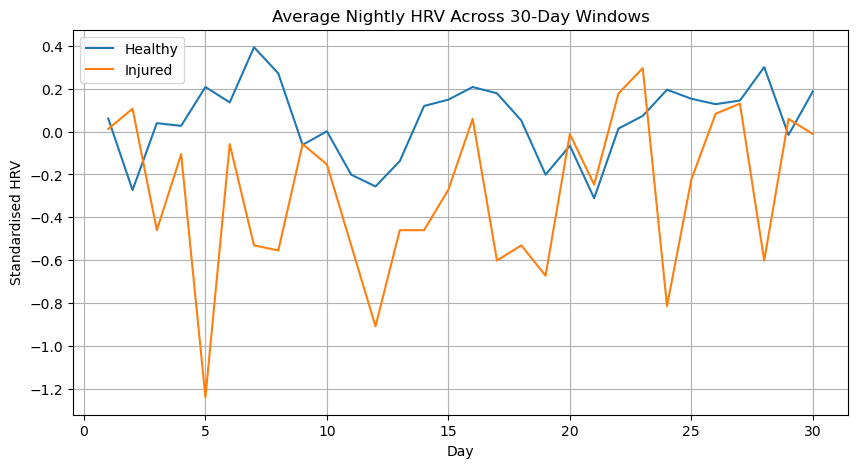

In [30]:
import matplotlib.pyplot as plt

healthy_mask = y == "Healthy"
injured_mask = y == "Injured"

feature = features.index("nightly_hrv_ms")

healthy_mean = X_scaled[healthy_mask, feature, :].mean(axis=0)
injured_mean = X_scaled[injured_mask, feature, :].mean(axis=0)

days = np.arange(1, 31)

plt.figure(figsize=(10,5))

plt.plot(days, healthy_mean, label="Healthy")
plt.plot(days, injured_mean, label="Injured")

plt.xlabel("Day")
plt.ylabel("Standardised HRV")
plt.title("Average Nightly HRV Across 30-Day Windows")

plt.grid(True)
plt.legend()

plt.show()

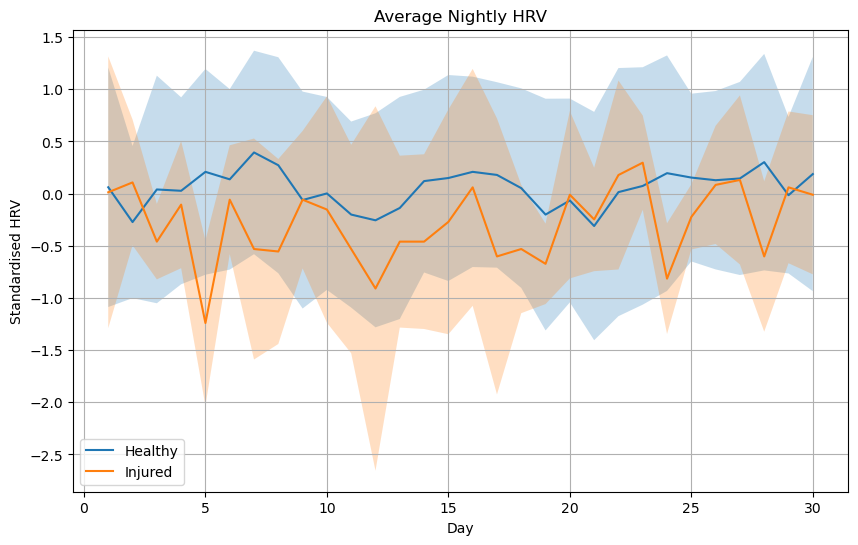

In [31]:
healthy = X_scaled[healthy_mask, feature, :]
injured = X_scaled[injured_mask, feature, :]

healthy_mean = healthy.mean(axis=0)
healthy_std = healthy.std(axis=0)

injured_mean = injured.mean(axis=0)
injured_std = injured.std(axis=0)

plt.figure(figsize=(10,6))

plt.plot(days, healthy_mean, label="Healthy")
plt.fill_between(days,
                 healthy_mean-healthy_std,
                 healthy_mean+healthy_std,
                 alpha=0.25)

plt.plot(days, injured_mean, label="Injured")
plt.fill_between(days,
                 injured_mean-injured_std,
                 injured_mean+injured_std,
                 alpha=0.25)

plt.xlabel("Day")
plt.ylabel("Standardised HRV")
plt.title("Average Nightly HRV")

plt.grid(True)
plt.legend()

plt.show()

In [32]:
X_flat = X_scaled.reshape(
    X_scaled.shape[0],
    -1
)

print(X_flat.shape)

(33, 330)


## PCA

In [33]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_flat)

print(X_pca.shape)

(33, 2)


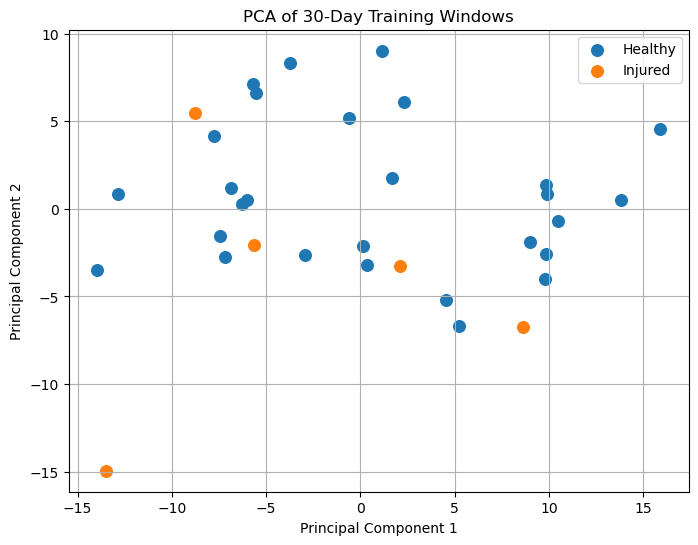

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

healthy = y == "Healthy"
injured = y == "Injured"

plt.scatter(
    X_pca[healthy,0],
    X_pca[healthy,1],
    label="Healthy",
    s=70
)

plt.scatter(
    X_pca[injured,0],
    X_pca[injured,1],
    label="Injured",
    s=70
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of 30-Day Training Windows")

plt.grid(True)
plt.legend()

plt.show()

In [35]:
print("Explained variance ratio:")

print(pca.explained_variance_ratio_)

print()

print("Total explained variance:")

print(np.sum(pca.explained_variance_ratio_))

Explained variance ratio:
[0.20505695 0.07601003]

Total explained variance:
0.28106697866553454


In [36]:
summary = pd.DataFrame({
    "Metric": [
        "Number of samples",
        "Healthy samples",
        "Injured samples",
        "Variables per day",
        "Days per sample",
        "Features after flattening",
        "Missing values",
        "PC1 variance explained",
        "PC2 variance explained",
        "Total variance explained"
    ],
    "Value": [
        X.shape[0],
        np.sum(y == "Healthy"),
        np.sum(y == "Injured"),
        X.shape[1],
        X.shape[2],
        X_flat.shape[1],
        np.isnan(X_scaled).sum(),
        round(pca.explained_variance_ratio_[0] * 100, 2),
        round(pca.explained_variance_ratio_[1] * 100, 2),
        round(np.sum(pca.explained_variance_ratio_) * 100, 2)
    ]
})

summary

,Metric,Value
0,Number of samples,33.00
1,Healthy samples,28.00
2,Injured samples,5.00
3,Variables per day,11.00
4,Days per sample,30.00
5,Features after flattening,330.00
6,Missing values,0.00
7,PC1 variance explained,20.51
8,PC2 variance explained,7.60
9,Total variance explained,28.11


In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np

# Number of clusters
k = 3

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=20
)

# Cluster the samples using their PCA coordinates
clusters = kmeans.fit_predict(X_pca)

print("Cluster assignments:")
print(clusters)

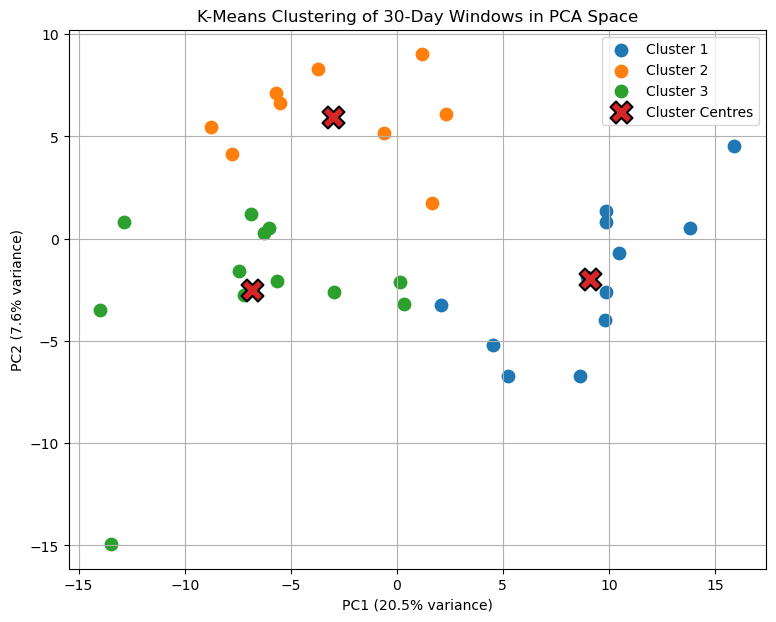

In [105]:
plt.figure(figsize=(9, 7))

for cluster in range(k):

    mask = clusters == cluster

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        s=80,
        label=f"Cluster {cluster + 1}"
    )

# Plot cluster centres
centres = kmeans.cluster_centers_

plt.scatter(
    centres[:, 0],
    centres[:, 1],
    marker="X",
    s=250,
    edgecolor="black",
    linewidth=1.5,
    label="Cluster Centres"
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variance)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variance)"
)

plt.title("K-Means Clustering of 30-Day Windows in PCA Space")

plt.legend()
plt.grid(True)

plt.show()

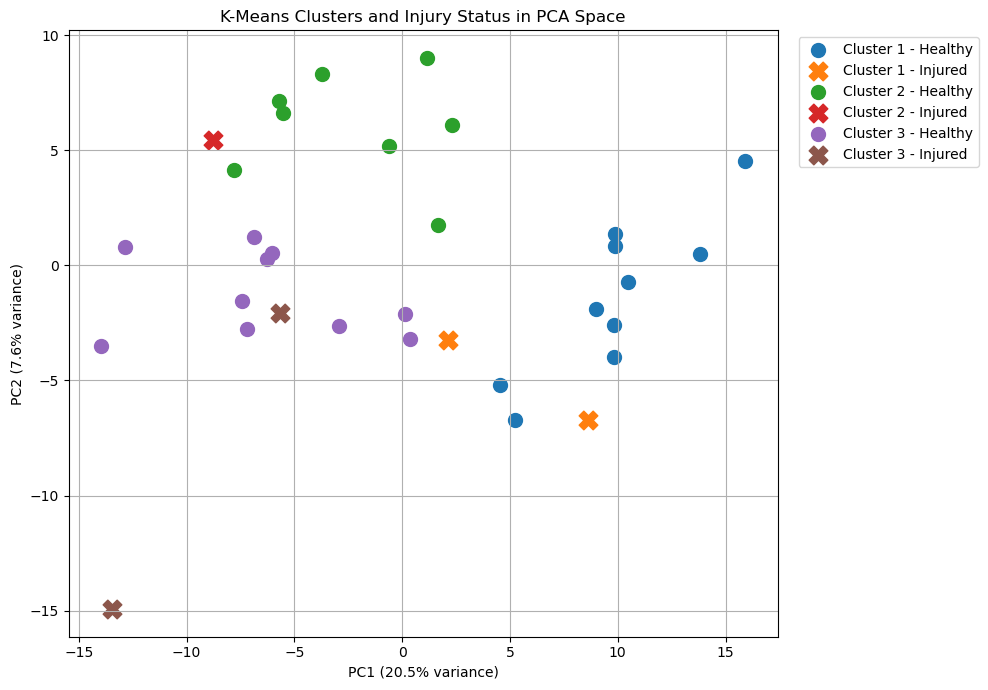

In [106]:
plt.figure(figsize=(10, 7))

markers = {
    "Healthy": "o",
    "Injured": "X"
}

for cluster in range(k):

    for status in ["Healthy", "Injured"]:

        mask = (
            (clusters == cluster) &
            (y == status)
        )

        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            s=100 if status == "Healthy" else 180,
            marker=markers[status],
            label=f"Cluster {cluster + 1} - {status}"
        )

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variance)"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variance)"
)

plt.title("K-Means Clusters and Injury Status in PCA Space")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(True)
plt.tight_layout()

plt.show()

In [107]:
cluster_results = pd.DataFrame({
    "Sample": np.arange(1, len(y) + 1),
    "Status": y,
    "Cluster": clusters + 1,
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1]
})

cluster_results

,Sample,Status,Cluster,PC1,PC2
0,1,Healthy,1,9.861937,1.348655
1,2,Healthy,3,-7.426207,-1.563868
2,3,Injured,1,8.639887,-6.714620
3,4,Healthy,1,5.245229,-6.698673
4,5,Healthy,1,9.811550,-3.994858
5,6,Healthy,1,4.526349,-5.200523
6,7,Healthy,1,10.496289,-0.716725
7,8,Healthy,1,9.843544,-2.590985
8,9,Healthy,3,0.345549,-3.190309
9,10,Healthy,1,8.988441,-1.872449


In [108]:
cluster_status = pd.crosstab(
    cluster_results["Cluster"],
    cluster_results["Status"]
)

cluster_status

Status,Healthy,Injured
Cluster,,
1,10,2
2,8,1
3,10,2


## PCA Permutation test 

In [38]:
import numpy as np

healthy_mask = y == "Healthy"
injured_mask = y == "Injured"

healthy_centroid = X_pca[healthy_mask].mean(axis=0)
injured_centroid = X_pca[injured_mask].mean(axis=0)

observed_distance = np.linalg.norm(
    healthy_centroid - injured_centroid
)

print("Observed centroid distance:", observed_distance)

Observed centroid distance: 6.4811771336497435


In [39]:
n_permutations = 5000
rng = np.random.RandomState(42)

permuted_distances = []

for i in range(n_permutations):

    shuffled_y = rng.permutation(y)

    shuffled_healthy = shuffled_y == "Healthy"
    shuffled_injured = shuffled_y == "Injured"

    healthy_centroid_perm = X_pca[
        shuffled_healthy
    ].mean(axis=0)

    injured_centroid_perm = X_pca[
        shuffled_injured
    ].mean(axis=0)

    distance = np.linalg.norm(
        healthy_centroid_perm
        - injured_centroid_perm
    )

    permuted_distances.append(distance)

permuted_distances = np.array(permuted_distances)

In [40]:
p_value = (
    np.sum(permuted_distances >= observed_distance) + 1
) / (
    n_permutations + 1
)

print("Observed centroid distance:", round(observed_distance, 3))
print("Permutation p-value:", round(p_value, 4))

Observed centroid distance: 6.481
Permutation p-value: 0.155


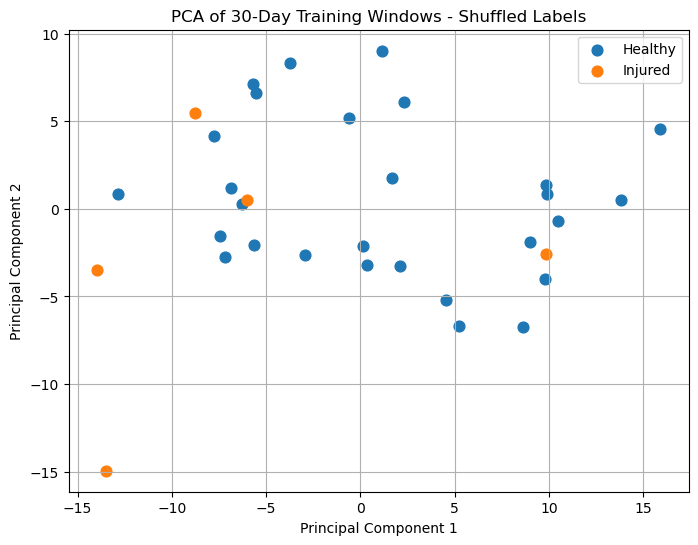

In [41]:
# Create one random shuffle of the labels
rng_plot = np.random.RandomState(42)
shuffled_y_plot = rng_plot.permutation(y)

# Plot PCA using shuffled labels
plt.figure(figsize=(8, 6))

for status in ["Healthy", "Injured"]:

    mask = shuffled_y_plot == status

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=status,
        s=60
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of 30-Day Training Windows - Shuffled Labels")

plt.legend()
plt.grid(True)

plt.show()

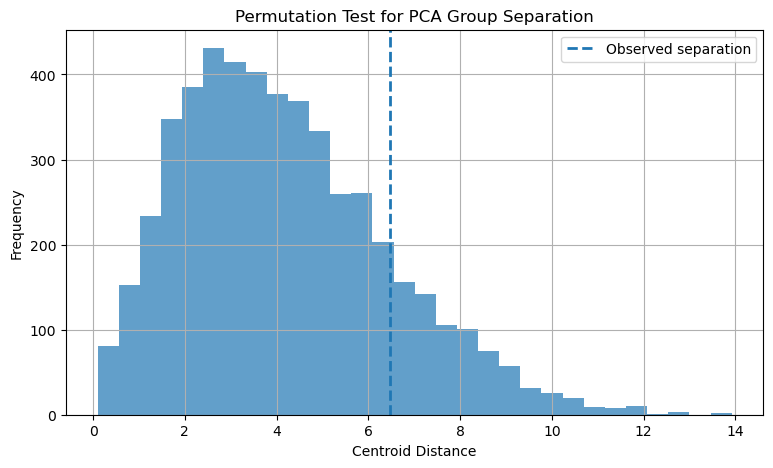

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    permuted_distances,
    bins=30,
    alpha=0.7
)

plt.axvline(
    observed_distance,
    linestyle="--",
    linewidth=2,
    label="Observed separation"
)

plt.xlabel("Centroid Distance")
plt.ylabel("Frequency")
plt.title("Permutation Test for PCA Group Separation")

plt.legend()
plt.grid(True)

plt.show()

## Anomoly Detection

In [43]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(
    n_estimators=300,
    contamination="auto",
    random_state=42
)

iso.fit(X_flat)

IsolationForest(n_estimators=300, random_state=42)

In [44]:
scores = iso.decision_function(X_flat)

predictions = iso.predict(X_flat)

results = pd.DataFrame({
    "Sample": np.arange(1, len(y)+1),
    "Status": y,
    "Anomaly Score": scores,
    "Prediction": predictions
})

results.head()

,Sample,Status,Anomaly Score,Prediction
0,1,Healthy,0.040411,1
1,2,Healthy,0.013411,1
2,3,Injured,0.027141,1
3,4,Healthy,0.024273,1
4,5,Healthy,0.029836,1


In [45]:
results["Prediction"] = results["Prediction"].map({
    1: "Normal",
    -1: "Anomaly"
})

results

,Sample,Status,Anomaly Score,Prediction
0,1,Healthy,0.040411,Normal
1,2,Healthy,0.013411,Normal
2,3,Injured,0.027141,Normal
3,4,Healthy,0.024273,Normal
4,5,Healthy,0.029836,Normal
5,6,Healthy,0.039271,Normal
6,7,Healthy,0.014092,Normal
7,8,Healthy,0.041448,Normal
8,9,Healthy,0.025531,Normal
9,10,Healthy,0.038821,Normal


In [46]:
print(results["Prediction"].value_counts())

Prediction
Normal     31
Anomaly     2
Name: count, dtype: int64


In [47]:
pd.crosstab(
    results["Status"],
    results["Prediction"]
)

Prediction,Anomaly,Normal
Status,,
Healthy,1,27
Injured,1,4


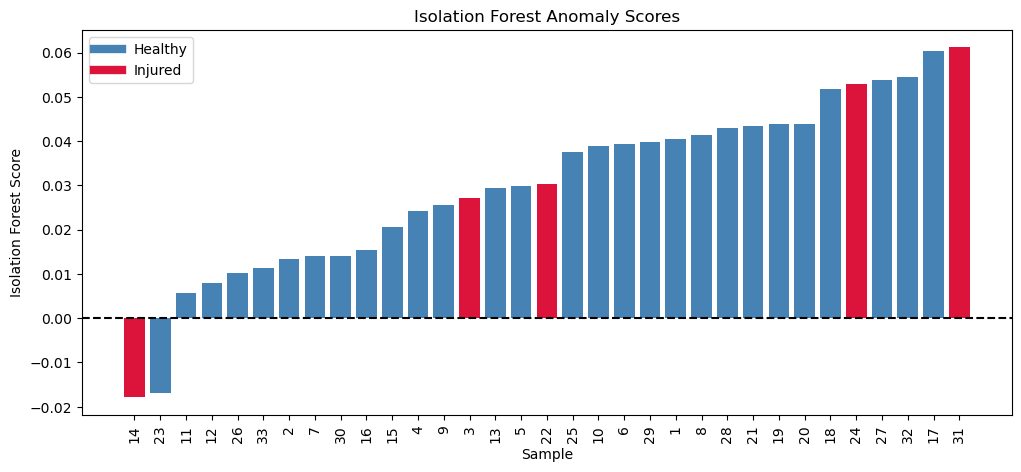

In [48]:
import matplotlib.pyplot as plt

results_sorted = results.sort_values("Anomaly Score")

colours = results_sorted["Status"].map({
    "Healthy": "steelblue",
    "Injured": "crimson"
})

plt.figure(figsize=(12,5))

plt.bar(
    results_sorted["Sample"].astype(str),
    results_sorted["Anomaly Score"],
    color=colours
)

plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Sample")
plt.ylabel("Isolation Forest Score")
plt.title("Isolation Forest Anomaly Scores")

plt.xticks(rotation=90)

from matplotlib.lines import Line2D

legend = [
    Line2D([0],[0], color="steelblue", lw=6, label="Healthy"),
    Line2D([0],[0], color="crimson", lw=6, label="Injured")
]

plt.legend(handles=legend)

plt.show()

In [49]:
from scipy.stats import linregress

temporal_features = []

for sample_index in range(X_scaled.shape[0]):

    sample_features = []

    for feature_index in range(X_scaled.shape[1]):

        series = X_scaled[sample_index, feature_index, :]

        # 1. Mean
        mean_value = np.mean(series)

        # 2. Standard deviation
        std_value = np.std(series)

        # 3. Trend across 30 days
        slope = linregress(
            np.arange(1, 31),
            series
        ).slope

        # 4. Minimum
        min_value = np.min(series)

        # 5. Maximum
        max_value = np.max(series)

        # 6. Change from first 7 days to final 7 days
        first_week = np.mean(series[:7])
        final_week = np.mean(series[-7:])

        week_change = final_week - first_week

        sample_features.extend([
            mean_value,
            std_value,
            slope,
            min_value,
            max_value,
            week_change
        ])

    temporal_features.append(sample_features)

X_temporal = np.array(temporal_features)

print(X_temporal.shape)

(33, 66)


In [50]:
iso_temporal = IsolationForest(
    n_estimators=300,
    contamination="auto",
    random_state=42
)

iso_temporal.fit(X_temporal)

IsolationForest(n_estimators=300, random_state=42)

In [51]:
temporal_scores = iso_temporal.decision_function(X_temporal)

temporal_predictions = iso_temporal.predict(X_temporal)

In [52]:
temporal_results = pd.DataFrame({
    "Sample": np.arange(1, len(y) + 1),
    "Status": y,
    "Anomaly Score": temporal_scores,
    "Prediction": temporal_predictions
})

temporal_results["Prediction"] = temporal_results["Prediction"].map({
    1: "Normal",
    -1: "Anomaly"
})

temporal_results

,Sample,Status,Anomaly Score,Prediction
0,1,Healthy,0.004084,Normal
1,2,Healthy,-0.017322,Anomaly
2,3,Injured,0.018301,Normal
3,4,Healthy,0.087891,Normal
4,5,Healthy,0.068591,Normal
5,6,Healthy,0.053057,Normal
6,7,Healthy,0.076085,Normal
7,8,Healthy,0.042306,Normal
8,9,Healthy,0.020881,Normal
9,10,Healthy,0.087399,Normal


In [53]:
pd.crosstab(
    temporal_results["Status"],
    temporal_results["Prediction"]
)

Prediction,Anomaly,Normal
Status,,
Healthy,2,26
Injured,1,4


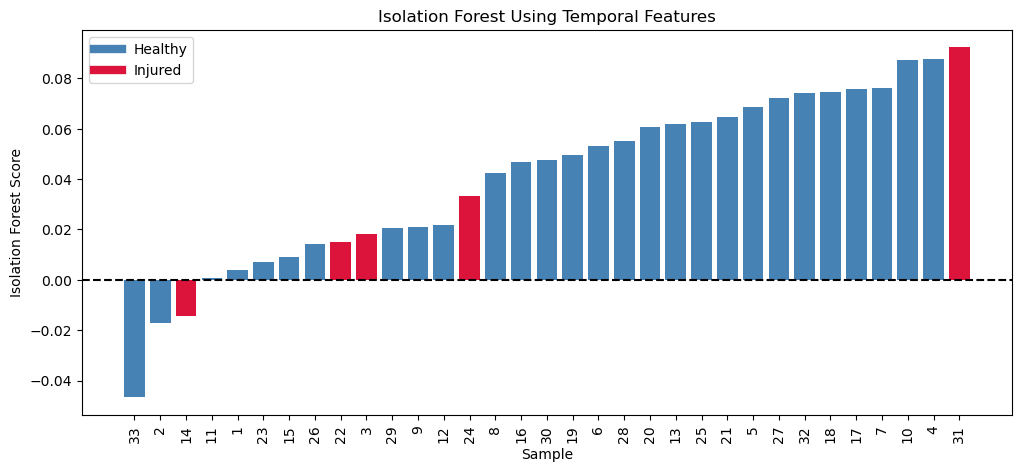

In [54]:
temporal_sorted = temporal_results.sort_values(
    "Anomaly Score"
)

colours = temporal_sorted["Status"].map({
    "Healthy": "steelblue",
    "Injured": "crimson"
})

plt.figure(figsize=(12,5))

plt.bar(
    temporal_sorted["Sample"].astype(str),
    temporal_sorted["Anomaly Score"],
    color=colours
)

plt.axhline(
    0,
    color="black",
    linestyle="--"
)

plt.xlabel("Sample")
plt.ylabel("Isolation Forest Score")

plt.title(
    "Isolation Forest Using Temporal Features"
)

plt.xticks(rotation=90)

from matplotlib.lines import Line2D

legend = [
    Line2D([0], [0], color="steelblue", lw=6, label="Healthy"),
    Line2D([0], [0], color="crimson", lw=6, label="Injured")
]

plt.legend(handles=legend)

plt.show()

In [55]:
pd.crosstab(
    temporal_results["Status"],
    temporal_results["Prediction"]
)

Prediction,Anomaly,Normal
Status,,
Healthy,2,26
Injured,1,4


## Aeon

In [56]:
import aeon

print(aeon.__version__)

1.5.0


In [57]:
from aeon.anomaly_detection.series.distance_based import KMeansAD

In [58]:
sample = X_scaled[0]

print(sample.shape)

(11, 30)


In [ ]:
detector = KMeansAD(
    n_clusters=3,
    window_size=5,
    stride=1,
    random_state=42
)

scores_sample = detector.fit_predict(
    sample,
    axis=1
)

print(scores_sample)
print(scores_sample.shape)

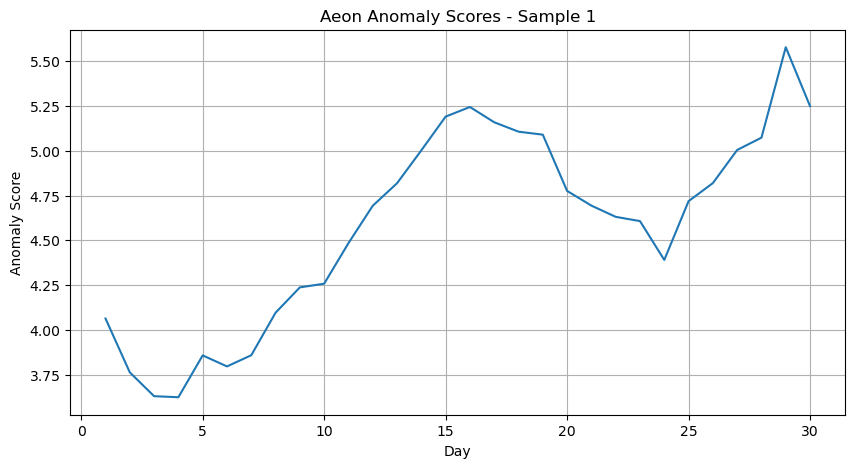

In [60]:
plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(1, len(scores_sample) + 1),
    scores_sample
)

plt.xlabel("Day")
plt.ylabel("Anomaly Score")
plt.title("Aeon Anomaly Scores - Sample 1")

plt.grid(True)

plt.show()

In [61]:
import warnings

warnings.filterwarnings(
    "ignore",
    message="KMeans is known to have a memory leak on Windows with MKL"
)

In [62]:
aeon_scores = []

for i in range(X_scaled.shape[0]):

    sample = X_scaled[i]

    detector = KMeansAD(
        n_clusters=3,
        window_size=5,
        stride=1,
        random_state=42
    )

    sample_scores = detector.fit_predict(
        sample,
        axis=1
    )

    aeon_scores.append(sample_scores)

In [63]:
print(len(aeon_scores))

33


In [64]:
print(aeon_scores[0].shape)

(30,)


In [65]:
aeon_summary = pd.DataFrame({
    "Sample": np.arange(1, len(y) + 1),
    "Status": y,
    "Mean Anomaly Score": [
        np.mean(scores) for scores in aeon_scores
    ],
    "Max Anomaly Score": [
        np.max(scores) for scores in aeon_scores
    ],
    "Std Anomaly Score": [
        np.std(scores) for scores in aeon_scores
    ]
})

aeon_summary

,Sample,Status,Mean Anomaly Score,Max Anomaly Score,Std Anomaly Score
0,1,Healthy,4.583868,5.577303,0.542432
1,2,Healthy,5.044044,7.077726,0.845222
2,3,Injured,5.610853,6.724591,0.611881
3,4,Healthy,5.583901,6.723708,0.763565
4,5,Healthy,5.507136,6.886360,0.645699
5,6,Healthy,5.465189,6.676218,0.461681
6,7,Healthy,5.421570,6.278543,0.499866
7,8,Healthy,4.552271,5.340539,0.497024
8,9,Healthy,5.364562,6.772769,0.853112
9,10,Healthy,5.363488,6.422790,0.760481


In [66]:
aeon_summary_sorted = aeon_summary.sort_values(
    "Max Anomaly Score",
    ascending=False
)

aeon_summary_sorted

,Sample,Status,Mean Anomaly Score,Max Anomaly Score,Std Anomaly Score
32,33,Healthy,7.698331,11.565240,1.667950
14,15,Healthy,6.583669,9.057457,1.028876
21,22,Injured,6.412173,8.625407,0.916631
18,19,Healthy,5.293614,8.275571,1.172848
24,25,Healthy,5.487510,7.894214,1.022447
13,14,Injured,6.163895,7.768423,1.025406
16,17,Healthy,5.394937,7.133579,0.748803
1,2,Healthy,5.044044,7.077726,0.845222
4,5,Healthy,5.507136,6.886360,0.645699
8,9,Healthy,5.364562,6.772769,0.853112


In [67]:
print(
    aeon_summary.groupby("Status")[
        ["Mean Anomaly Score", "Max Anomaly Score", "Std Anomaly Score"]
    ].mean()
)

         Mean Anomaly Score  Max Anomaly Score  Std Anomaly Score
Status                                                           
Healthy            5.098879           6.469647           0.673879
Injured            5.509992           6.799445           0.698134


In [ ]:
plt.figure(figsize=(10, 5))

healthy_scores = aeon_summary[
    aeon_summary["Status"] == "Healthy"
]["Max Anomaly Score"]

injured_scores = aeon_summary[
    aeon_summary["Status"] == "Injured"
]["Max Anomaly Score"]

plt.boxplot(
    [healthy_scores, injured_scores],
    labels=["Healthy", "Injured"]
)

plt.ylabel("Maximum Aeon Anomaly Score")
plt.title("Maximum Anomaly Scores: Healthy vs Injured")

plt.grid(True)

plt.show()

In [69]:
from scipy.stats import mannwhitneyu

healthy_scores = aeon_summary[
    aeon_summary["Status"] == "Healthy"
]["Max Anomaly Score"]

injured_scores = aeon_summary[
    aeon_summary["Status"] == "Injured"
]["Max Anomaly Score"]

statistic, p_value = mannwhitneyu(
    healthy_scores,
    injured_scores,
    alternative="two-sided"
)

print("U statistic:", statistic)
print("p-value:", p_value)

U statistic: 56.0
p-value: 0.5094970843024236


In [70]:
aeon_summary.sort_values(
    "Max Anomaly Score",
    ascending=False
)

,Sample,Status,Mean Anomaly Score,Max Anomaly Score,Std Anomaly Score
32,33,Healthy,7.698331,11.565240,1.667950
14,15,Healthy,6.583669,9.057457,1.028876
21,22,Injured,6.412173,8.625407,0.916631
18,19,Healthy,5.293614,8.275571,1.172848
24,25,Healthy,5.487510,7.894214,1.022447
13,14,Injured,6.163895,7.768423,1.025406
16,17,Healthy,5.394937,7.133579,0.748803
1,2,Healthy,5.044044,7.077726,0.845222
4,5,Healthy,5.507136,6.886360,0.645699
8,9,Healthy,5.364562,6.772769,0.853112


## Evaluating anomoly scores

In [71]:
from sklearn.metrics import roc_auc_score, average_precision_score

# Convert labels to binary values
# Healthy = 0
# Injured = 1

y_binary = np.where(y == "Injured", 1, 0)

print(y_binary)
print("Injuries:", y_binary.sum())

[0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 0]
Injuries: 5


In [72]:
iso_anomaly_score = -scores

iso_roc_auc = roc_auc_score(
    y_binary,
    iso_anomaly_score
)

iso_pr_auc = average_precision_score(
    y_binary,
    iso_anomaly_score
)

print("Isolation Forest - Flattened")
print("ROC-AUC:", round(iso_roc_auc, 3))
print("PR-AUC:", round(iso_pr_auc, 3))

Isolation Forest - Flattened
ROC-AUC: 0.436
PR-AUC: 0.322


In [73]:
temporal_anomaly_score = -temporal_scores

temporal_roc_auc = roc_auc_score(
    y_binary,
    temporal_anomaly_score
)

temporal_pr_auc = average_precision_score(
    y_binary,
    temporal_anomaly_score
)

print("Isolation Forest - Temporal Features")
print("ROC-AUC:", round(temporal_roc_auc, 3))
print("PR-AUC:", round(temporal_pr_auc, 3))

Isolation Forest - Temporal Features
ROC-AUC: 0.614
PR-AUC: 0.259


In [74]:
window_anomaly_scores = np.array([
    np.max(sample_scores)
    for sample_scores in aeon_scores
])

In [75]:
aeon_roc_auc = roc_auc_score(
    y_binary,
    window_anomaly_scores
)

aeon_pr_auc = average_precision_score(
    y_binary,
    window_anomaly_scores
)

print("Aeon KMeansAD")
print("ROC-AUC:", round(aeon_roc_auc, 3))
print("PR-AUC:", round(aeon_pr_auc, 3))

Aeon KMeansAD
ROC-AUC: 0.6
PR-AUC: 0.258


In [76]:
auc_results = pd.DataFrame({
    "Method": [
        "Isolation Forest - Flattened",
        "Isolation Forest - Temporal Features",
        "Aeon KMeansAD"
    ],
    
    "ROC-AUC": [
        iso_roc_auc,
        temporal_roc_auc,
        aeon_roc_auc
    ],
    
    "PR-AUC": [
        iso_pr_auc,
        temporal_pr_auc,
        aeon_pr_auc
    ]
})

auc_results = auc_results.round(3)

auc_results

,Method,ROC-AUC,PR-AUC
0,Isolation Forest - Flattened,0.436,0.322
1,Isolation Forest - Temporal Features,0.614,0.259
2,Aeon KMeansAD,0.600,0.258


## bootsrap function

In [77]:
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score

def bootstrap_auc(y_true, scores, n_bootstraps=5000, random_state=42):

    rng = np.random.RandomState(random_state)

    roc_scores = []
    pr_scores = []

    n = len(y_true)

    for i in range(n_bootstraps):

        # Randomly sample the 33 windows WITH replacement
        indices = rng.randint(0, n, n)

        y_sample = y_true[indices]
        score_sample = scores[indices]

        # ROC-AUC cannot be calculated if the bootstrap
        # sample contains only one class
        if len(np.unique(y_sample)) < 2:
            continue

        roc_scores.append(
            roc_auc_score(y_sample, score_sample)
        )

        pr_scores.append(
            average_precision_score(y_sample, score_sample)
        )

    roc_scores = np.array(roc_scores)
    pr_scores = np.array(pr_scores)

    return {
        "ROC-AUC": roc_auc_score(y_true, scores),
        "ROC Lower": np.percentile(roc_scores, 2.5),
        "ROC Upper": np.percentile(roc_scores, 97.5),

        "PR-AUC": average_precision_score(y_true, scores),
        "PR Lower": np.percentile(pr_scores, 2.5),
        "PR Upper": np.percentile(pr_scores, 97.5)
    }

In [78]:
iso_anomaly_score = -scores
temporal_anomaly_score = -temporal_scores

aeon_anomaly_score = window_anomaly_scores

In [79]:
iso_bootstrap = bootstrap_auc(
    y_binary,
    iso_anomaly_score
)

temporal_bootstrap = bootstrap_auc(
    y_binary,
    temporal_anomaly_score
)

aeon_bootstrap = bootstrap_auc(
    y_binary,
    aeon_anomaly_score
)

In [80]:
bootstrap_results = pd.DataFrame([
    {
        "Method": "Isolation Forest - Flattened",
        **iso_bootstrap
    },

    {
        "Method": "Isolation Forest - Temporal",
        **temporal_bootstrap
    },

    {
        "Method": "Aeon KMeansAD",
        **aeon_bootstrap
    }
])

bootstrap_results = bootstrap_results.round(3)

bootstrap_results

,Method,ROC-AUC,ROC Lower,ROC Upper,PR-AUC,PR Lower,PR Upper
0,Isolation Forest - Flattened,0.436,0.065,0.813,0.322,0.059,0.717
1,Isolation Forest - Temporal,0.614,0.256,0.889,0.259,0.083,0.639
2,Aeon KMeansAD,0.600,0.258,0.906,0.258,0.082,0.667


In [81]:
display_results = pd.DataFrame({
    "Method": bootstrap_results["Method"],

    "ROC-AUC (95% CI)": [
        f"{row['ROC-AUC']:.3f} "
        f"({row['ROC Lower']:.3f}–{row['ROC Upper']:.3f})"
        for _, row in bootstrap_results.iterrows()
    ],

    "PR-AUC (95% CI)": [
        f"{row['PR-AUC']:.3f} "
        f"({row['PR Lower']:.3f}–{row['PR Upper']:.3f})"
        for _, row in bootstrap_results.iterrows()
    ]
})

display_results

,Method,ROC-AUC (95% CI),PR-AUC (95% CI)
0,Isolation Forest - Flattened,0.436 (0.065–0.813),0.322 (0.059–0.717)
1,Isolation Forest - Temporal,0.614 (0.256–0.889),0.259 (0.083–0.639)
2,Aeon KMeansAD,0.600 (0.258–0.906),0.258 (0.082–0.667)


## anomoly behaviour changes approaching injury date 

In [82]:
period_results = []

for i, sample_scores in enumerate(aeon_scores):

    early = np.mean(sample_scores[0:10])
    middle = np.mean(sample_scores[10:20])
    late = np.mean(sample_scores[20:30])

    period_results.append({
        "Sample": i + 1,
        "Status": y[i],
        "Days 1-10": early,
        "Days 11-20": middle,
        "Days 21-30": late
    })

period_results = pd.DataFrame(period_results)

period_results

,Sample,Status,Days 1-10,Days 11-20,Days 21-30
0,1,Healthy,3.918976,4.956227,4.876399
1,2,Healthy,5.326665,4.794640,5.010828
2,3,Injured,5.661864,4.950057,6.220638
3,4,Healthy,4.839289,5.833862,6.078553
4,5,Healthy,5.433874,4.953810,6.133726
5,6,Healthy,5.862898,5.146616,5.386055
6,7,Healthy,5.464391,5.499908,5.300410
7,8,Healthy,3.964759,4.586634,5.105419
8,9,Healthy,6.227543,4.562089,5.304053
9,10,Healthy,5.617538,5.797774,4.675153


In [83]:
period_means = period_results.groupby("Status")[
    ["Days 1-10", "Days 11-20", "Days 21-30"]
].mean()

period_means

,Days 1-10,Days 11-20,Days 21-30
Status,,,
Healthy,5.147880,4.935527,5.213230
Injured,5.426137,5.772244,5.331596


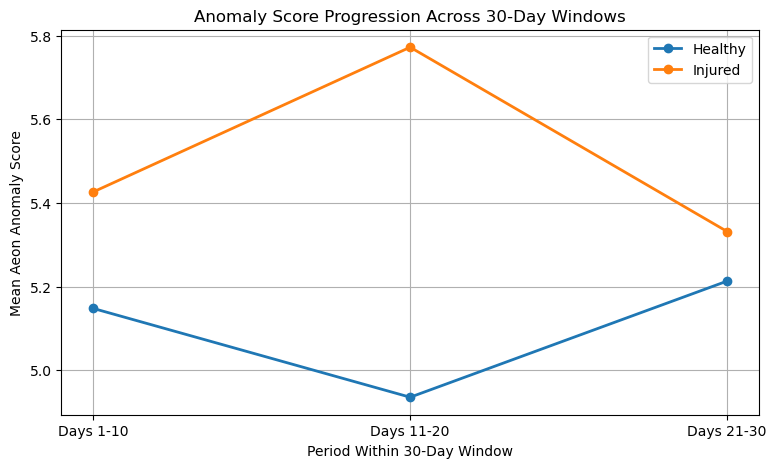

In [84]:
import matplotlib.pyplot as plt

period_labels = [
    "Days 1-10",
    "Days 11-20",
    "Days 21-30"
]

healthy_means = period_means.loc["Healthy", period_labels]
injured_means = period_means.loc["Injured", period_labels]

plt.figure(figsize=(9, 5))

plt.plot(
    period_labels,
    healthy_means,
    marker="o",
    linewidth=2,
    label="Healthy"
)

plt.plot(
    period_labels,
    injured_means,
    marker="o",
    linewidth=2,
    label="Injured"
)

plt.xlabel("Period Within 30-Day Window")
plt.ylabel("Mean Aeon Anomaly Score")
plt.title("Anomaly Score Progression Across 30-Day Windows")

plt.legend()
plt.grid(True)

plt.show()

In [85]:
period_results["Late-Early Change"] = (
    period_results["Days 21-30"]
    - period_results["Days 1-10"]
)

period_results[
    ["Sample", "Status", "Late-Early Change"]
].sort_values(
    "Late-Early Change",
    ascending=False
)

,Sample,Status,Late-Early Change
24,25,Healthy,1.925311
14,15,Healthy,1.458634
3,4,Healthy,1.239265
7,8,Healthy,1.140659
0,1,Healthy,0.957423
22,23,Healthy,0.943784
4,5,Healthy,0.699852
25,26,Healthy,0.696611
11,12,Healthy,0.654570
17,18,Healthy,0.560482


In [86]:
period_results.groupby("Status")[
    "Late-Early Change"
].agg(["mean", "median", "std"])

,mean,median,std
Status,,,
Healthy,0.065350,-0.053242,0.955426
Injured,-0.094541,-0.016967,0.560241


In [87]:
from scipy.stats import mannwhitneyu

healthy_change = period_results[
    period_results["Status"] == "Healthy"
]["Late-Early Change"]

injured_change = period_results[
    period_results["Status"] == "Injured"
]["Late-Early Change"]

u_stat, p_value = mannwhitneyu(
    healthy_change,
    injured_change,
    alternative="two-sided"
)

print("Mann-Whitney U:", round(u_stat, 3))
print("p-value:", round(p_value, 4))

Mann-Whitney U: 78.0
p-value: 0.715


## 11-20 day test

In [88]:
from scipy.stats import mannwhitneyu

healthy_middle = period_results[
    period_results["Status"] == "Healthy"
]["Days 11-20"]

injured_middle = period_results[
    period_results["Status"] == "Injured"
]["Days 11-20"]

u_middle, p_middle = mannwhitneyu(
    healthy_middle,
    injured_middle,
    alternative="two-sided"
)

print("Healthy mean:", round(healthy_middle.mean(), 3))
print("Injured mean:", round(injured_middle.mean(), 3))
print("Healthy median:", round(healthy_middle.median(), 3))
print("Injured median:", round(injured_middle.median(), 3))
print()
print("Mann-Whitney U:", round(u_middle, 3))
print("p-value:", round(p_middle, 4))

Healthy mean: 4.936
Injured mean: 5.772
Healthy median: 4.874
Injured median: 4.974

Mann-Whitney U: 44.0
p-value: 0.2074


In [89]:
n_healthy = len(healthy_middle)
n_injured = len(injured_middle)

# Orient effect size so positive values indicate
# higher scores in the injured group
u_injured = mannwhitneyu(
    injured_middle,
    healthy_middle,
    alternative="two-sided"
).statistic

rank_biserial = (
    (2 * u_injured) / (n_injured * n_healthy)
) - 1

print("Rank-biserial correlation:", round(rank_biserial, 3))

Rank-biserial correlation: 0.371


In [90]:
injured_periods = period_results[
    period_results["Status"] == "Injured"
][
    [
        "Sample",
        "Days 1-10",
        "Days 11-20",
        "Days 21-30"
    ]
]

injured_periods

,Sample,Days 1-10,Days 11-20,Days 21-30
2,3,5.661864,4.950057,6.220638
13,14,5.682293,7.183730,5.625662
21,22,6.062326,7.078128,6.096065
23,24,4.526239,4.674935,4.509272
30,31,5.197962,4.974371,4.206342


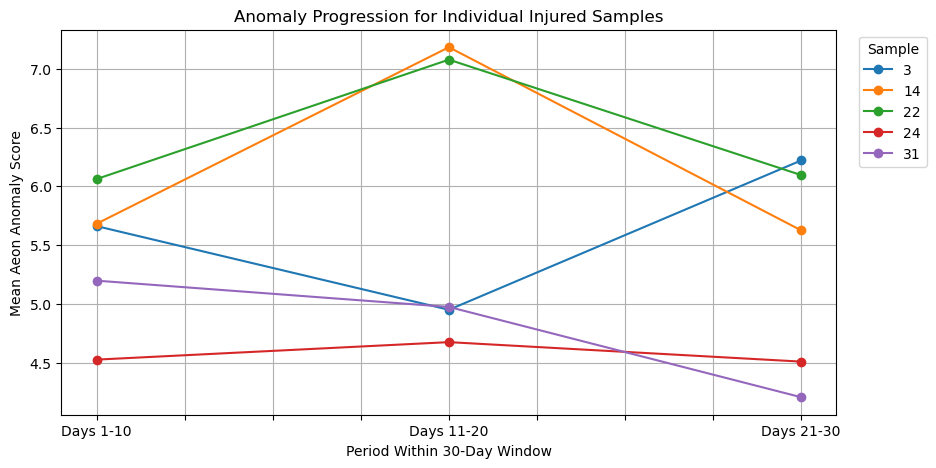

In [91]:
injured_periods.set_index("Sample").T.plot(
    figsize=(10, 5),
    marker="o"
)

plt.xlabel("Period Within 30-Day Window")
plt.ylabel("Mean Aeon Anomaly Score")
plt.title("Anomaly Progression for Individual Injured Samples")

plt.legend(
    title="Sample",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(True)
plt.show()

In [92]:
middle_feature_results = []

for i in range(X_scaled.shape[0]):

    for j, feature in enumerate(features):

        # Days 11-20
        values = X_scaled[i, j, 10:20]

        middle_feature_results.append({
            "Sample": i + 1,
            "Status": y[i],
            "Feature": feature,
            "Mean Absolute Z": np.mean(np.abs(values))
        })

middle_feature_results = pd.DataFrame(
    middle_feature_results
)

In [93]:
feature_comparison = (
    middle_feature_results
    .groupby(["Feature", "Status"])["Mean Absolute Z"]
    .mean()
    .unstack()
)

feature_comparison["Difference"] = (
    feature_comparison["Injured"]
    - feature_comparison["Healthy"]
)

feature_comparison = feature_comparison.sort_values(
    "Difference",
    ascending=False
)

feature_comparison

Status,Healthy,Injured,Difference
Feature,,,
avg_cadence_spm,0.627759,1.078768,0.451009
resting_heart_rate_bpm,0.742243,0.995588,0.253345
weekly_avg_hrv_ms,0.813214,1.061310,0.248097
avg_stress_level,0.749134,0.992380,0.243246
nightly_hrv_ms,0.785825,0.820704,0.034879
running_elapsed_time,0.856556,0.883902,0.027347
avg_ground_contact_ms,0.706463,0.717572,0.011109
sleep_score,0.712799,0.721324,0.008525
running_distance_km,0.863194,0.861684,-0.001511


## direction of change 

In [94]:
key_features = [
    "avg_cadence_spm",
    "resting_heart_rate_bpm",
    "weekly_avg_hrv_ms",
    "avg_stress_level"
]

key_features

['avg_cadence_spm',
 'resting_heart_rate_bpm',
 'weekly_avg_hrv_ms',
 'avg_stress_level']

In [95]:
for feature in key_features:
    print(feature, features.index(feature))

avg_cadence_spm 3
resting_heart_rate_bpm 6
weekly_avg_hrv_ms 9
avg_stress_level 7


In [96]:
direction_results = []

for i in range(X_scaled.shape[0]):

    for feature in key_features:

        j = features.index(feature)

        early = np.mean(X_scaled[i, j, 0:10])
        middle = np.mean(X_scaled[i, j, 10:20])
        late = np.mean(X_scaled[i, j, 20:30])

        direction_results.append({
            "Sample": i + 1,
            "Status": y[i],
            "Feature": feature,
            "Days 1-10": early,
            "Days 11-20": middle,
            "Days 21-30": late
        })

direction_results = pd.DataFrame(direction_results)

direction_results.head()

,Sample,Status,Feature,Days 1-10,Days 11-20,Days 21-30
0,1,Healthy,avg_cadence_spm,0.640581,0.041404,0.274671
1,1,Healthy,resting_heart_rate_bpm,0.201644,-0.660749,-1.299558
2,1,Healthy,weekly_avg_hrv_ms,-0.187315,1.062247,1.587425
3,1,Healthy,avg_stress_level,-0.329508,-0.274957,-1.184134
4,2,Healthy,avg_cadence_spm,-0.034065,0.295254,0.591793


In [97]:
direction_means = (
    direction_results
    .groupby(["Feature", "Status"])[
        ["Days 1-10", "Days 11-20", "Days 21-30"]
    ]
    .mean()
)

direction_means

Days 1-10  Days 11-20  Days 21-30
Feature                Status                                    
avg_cadence_spm        Healthy  -0.054415   -0.001347    0.098896
                       Injured  -0.107171   -0.011882   -0.122494
avg_stress_level       Healthy  -0.071691   -0.017141   -0.082082
                       Injured   0.266912    0.510572    0.179631
resting_heart_rate_bpm Healthy   0.005439   -0.130308   -0.124605
                       Injured   0.463556    0.521049    0.412452
weekly_avg_hrv_ms      Healthy   0.112140    0.053930    0.074627
                       Injured  -0.426362   -0.647299   -0.274242

In [98]:
middle_direction = (
    direction_results
    .groupby(["Feature", "Status"])["Days 11-20"]
    .mean()
    .unstack()
)

middle_direction["Difference"] = (
    middle_direction["Injured"]
    - middle_direction["Healthy"]
)

middle_direction = middle_direction.sort_values(
    "Difference",
    ascending=False
)

middle_direction

Status,Healthy,Injured,Difference
Feature,,,
resting_heart_rate_bpm,-0.130308,0.521049,0.651358
avg_stress_level,-0.017141,0.510572,0.527712
avg_cadence_spm,-0.001347,-0.011882,-0.010535
weekly_avg_hrv_ms,0.053930,-0.647299,-0.701230


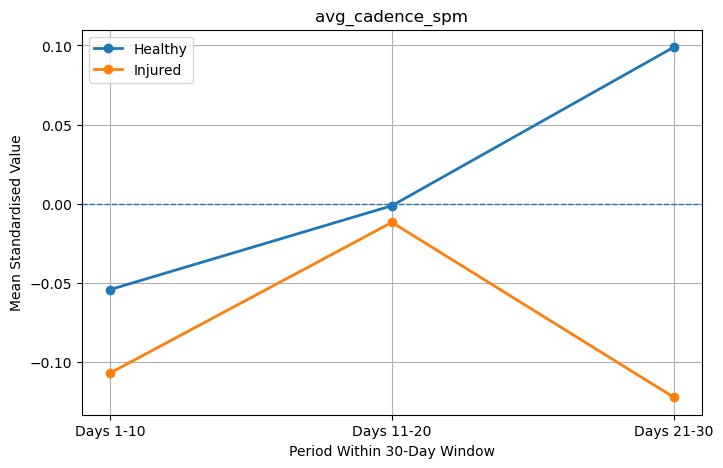

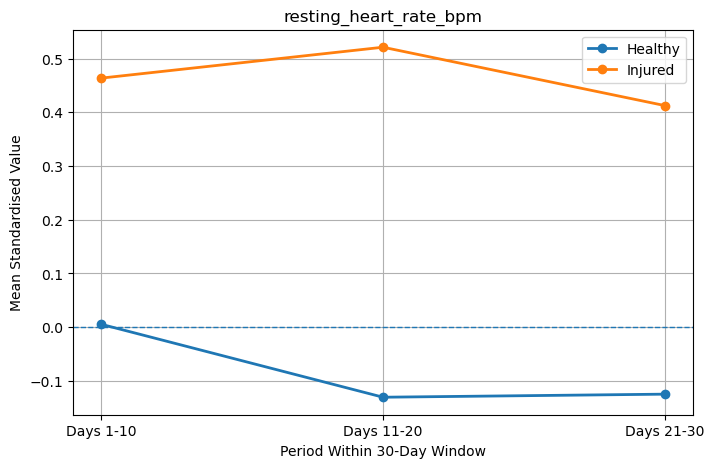

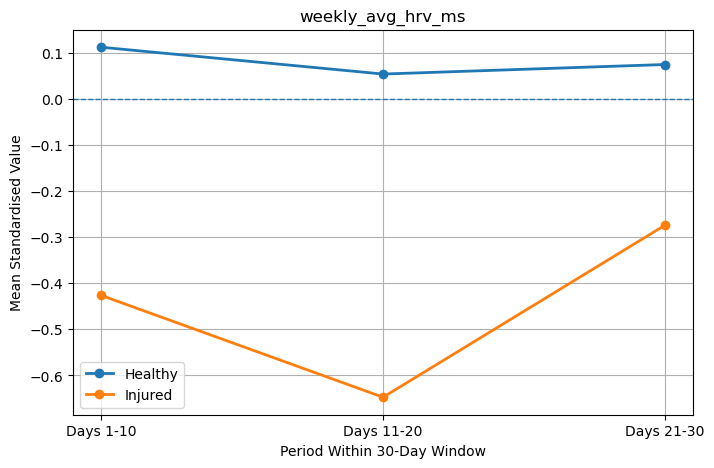

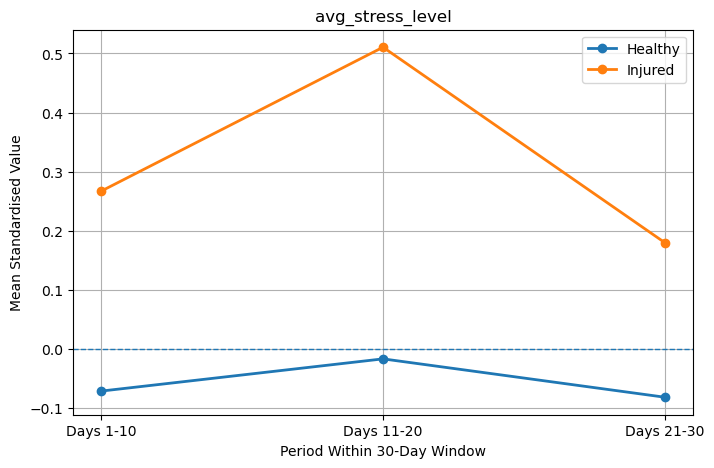

In [99]:
periods = [
    "Days 1-10",
    "Days 11-20",
    "Days 21-30"
]

for feature in key_features:

    subset = direction_results[
        direction_results["Feature"] == feature
    ]

    means = subset.groupby("Status")[periods].mean()

    plt.figure(figsize=(8, 5))

    plt.plot(
        periods,
        means.loc["Healthy"],
        marker="o",
        linewidth=2,
        label="Healthy"
    )

    plt.plot(
        periods,
        means.loc["Injured"],
        marker="o",
        linewidth=2,
        label="Injured"
    )

    plt.axhline(
        0,
        linestyle="--",
        linewidth=1
    )

    plt.xlabel("Period Within 30-Day Window")
    plt.ylabel("Mean Standardised Value")
    plt.title(feature)

    plt.legend()
    plt.grid(True)

    plt.show()

In [100]:
peak_cases = direction_results[
    direction_results["Sample"].isin([14, 22])
]

peak_cases

,Sample,Status,Feature,Days 1-10,Days 11-20,Days 21-30
52,14,Injured,avg_cadence_spm,0.082568,-0.338990,-0.013483
53,14,Injured,resting_heart_rate_bpm,1.734788,2.118074,1.511205
54,14,Injured,weekly_avg_hrv_ms,-1.509316,-2.523454,-0.893590
55,14,Injured,avg_stress_level,1.106991,1.052441,0.906973
84,22,Injured,avg_cadence_spm,-1.009825,-0.918348,-2.237911
85,22,Injured,resting_heart_rate_bpm,1.000157,0.361347,0.201644
86,22,Injured,weekly_avg_hrv_ms,-0.259754,-0.549507,-0.422740
87,22,Injured,avg_stress_level,0.379650,1.088808,-0.129489


In [101]:
peak_table = peak_cases.pivot(
    index="Feature",
    columns="Sample",
    values=[
        "Days 1-10",
        "Days 11-20",
        "Days 21-30"
    ]
)

peak_table.round(3)

Days 1-10       Days 11-20        Days 21-30       
Sample                        14    22         14     22         14     22
Feature                                                                   
avg_cadence_spm            0.083 -1.01     -0.339 -0.918     -0.013 -2.238
avg_stress_level           1.107  0.38      1.052  1.089      0.907 -0.129
resting_heart_rate_bpm     1.735  1.00      2.118  0.361      1.511  0.202
weekly_avg_hrv_ms         -1.509 -0.26     -2.523 -0.550     -0.894 -0.423

In [102]:
peak_cases = peak_cases.copy()

peak_cases["Early-Middle Change"] = (
    peak_cases["Days 11-20"]
    - peak_cases["Days 1-10"]
)

peak_cases[
    [
        "Sample",
        "Feature",
        "Days 1-10",
        "Days 11-20",
        "Early-Middle Change"
    ]
].sort_values(
    ["Sample", "Early-Middle Change"],
    ascending=[True, False]
)

,Sample,Feature,Days 1-10,Days 11-20,Early-Middle Change
53,14,resting_heart_rate_bpm,1.734788,2.118074,0.383286
55,14,avg_stress_level,1.106991,1.052441,-0.054551
52,14,avg_cadence_spm,0.082568,-0.338990,-0.421559
54,14,weekly_avg_hrv_ms,-1.509316,-2.523454,-1.014138
87,22,avg_stress_level,0.379650,1.088808,0.709158
84,22,avg_cadence_spm,-1.009825,-0.918348,0.091478
86,22,weekly_avg_hrv_ms,-0.259754,-0.549507,-0.289754
85,22,resting_heart_rate_bpm,1.000157,0.361347,-0.638810


## tests 

In [103]:
from scipy.stats import mannwhitneyu

test_features = [
    "resting_heart_rate_bpm",
    "avg_stress_level",
    "weekly_avg_hrv_ms",
    "avg_cadence_spm"
]

feature_stats = []

for feature in test_features:

    subset = direction_results[
        direction_results["Feature"] == feature
    ]

    healthy_values = subset[
        subset["Status"] == "Healthy"
    ]["Days 11-20"]

    injured_values = subset[
        subset["Status"] == "Injured"
    ]["Days 11-20"]

    # Mann-Whitney test
    u_stat, p_value = mannwhitneyu(
        injured_values,
        healthy_values,
        alternative="two-sided"
    )

    # Rank-biserial correlation
    n_injured = len(injured_values)
    n_healthy = len(healthy_values)

    rank_biserial = (
        (2 * u_stat) / (n_injured * n_healthy)
    ) - 1

    feature_stats.append({
        "Feature": feature,
        "Healthy Mean": healthy_values.mean(),
        "Injured Mean": injured_values.mean(),
        "Difference": injured_values.mean() - healthy_values.mean(),
        "Mann-Whitney U": u_stat,
        "p-value": p_value,
        "Rank-Biserial": rank_biserial
    })

feature_stats = pd.DataFrame(feature_stats)

feature_stats.round(3)

,Feature,Healthy Mean,Injured Mean,Difference,Mann-Whitney U,p-value,Rank-Biserial
0,resting_heart_rate_bpm,-0.130,0.521,0.651,99.5,0.145,0.421
1,avg_stress_level,-0.017,0.511,0.528,104.0,0.093,0.486
2,weekly_avg_hrv_ms,0.054,-0.647,-0.701,47.5,0.269,-0.321
3,avg_cadence_spm,-0.001,-0.012,-0.011,66.0,0.865,-0.057


In [104]:
feature_stats["Interpretation"] = np.where(
    feature_stats["Rank-Biserial"] > 0,
    "Higher in injured",
    "Lower in injured"
)

feature_stats[
    [
        "Feature",
        "Healthy Mean",
        "Injured Mean",
        "Difference",
        "Mann-Whitney U",
        "p-value",
        "Rank-Biserial",
        "Interpretation"
    ]
].round(3)

,Feature,Healthy Mean,Injured Mean,Difference,Mann-Whitney U,p-value,Rank-Biserial,Interpretation
0,resting_heart_rate_bpm,-0.130,0.521,0.651,99.5,0.145,0.421,Higher in injured
1,avg_stress_level,-0.017,0.511,0.528,104.0,0.093,0.486,Higher in injured
2,weekly_avg_hrv_ms,0.054,-0.647,-0.701,47.5,0.269,-0.321,Lower in injured
3,avg_cadence_spm,-0.001,-0.012,-0.011,66.0,0.865,-0.057,Lower in injured
